In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv("StudentsPerformance.csv")
df

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75
...,...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77


Questions I go from checking the data:
1.Does gender effect score?<br>
2.Does race effect score?<br>
3.Does parental education effect score?<br>
4.Does test prep effect score?<br>
I can't find any use of lunch table.

In [3]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df["race/ethnicity"].value_counts(ascending=True)

race/ethnicity
group A     89
group E    140
group B    190
group D    262
group C    319
Name: count, dtype: int64

In [6]:
df["parental level of education"].value_counts()

parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

In [7]:
df["lunch"].value_counts()
df["test preparation course"].value_counts()

test preparation course
none         642
completed    358
Name: count, dtype: int64

In [8]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [9]:
df.groupby("gender").mean(numeric_only=True)

,math score,reading score,writing score
gender,,,
female,63.633205,72.608108,72.467181
male,68.728216,65.473029,63.311203


so based on that i would conclude that female are performing much better in reading and writing and males are performing better in math.

In [10]:
df.groupby("race/ethnicity").mean(numeric_only=True)

,math score,reading score,writing score
race/ethnicity,,,
group A,61.629213,64.674157,62.674157
group B,63.452632,67.352632,65.600000
group C,64.463950,69.103448,67.827586
group D,67.362595,70.030534,70.145038
group E,73.821429,73.028571,71.407143


so group a is performing bad in math and group e is perfoming so great in math and overall too and a is lacking a lot.

In [11]:
df.groupby("parental level of education").mean(numeric_only=True)

,math score,reading score,writing score
parental level of education,,,
associate's degree,67.882883,70.927928,69.896396
bachelor's degree,69.389831,73.000000,73.381356
high school,62.137755,64.704082,62.448980
master's degree,69.745763,75.372881,75.677966
some college,67.128319,69.460177,68.840708
some high school,63.497207,66.938547,64.888268


so i would conclude that students whose parents have studied do significently perform less than those whose have studied a lot.

In [12]:
df.groupby("test preparation course").mean(numeric_only=True)

,math score,reading score,writing score
test preparation course,,,
completed,69.695531,73.893855,74.418994
none,64.077882,66.534268,64.504673


so those who have completed there test preparation perform significently better than those who don't

Axes(0.125,0.11;0.775x0.77)


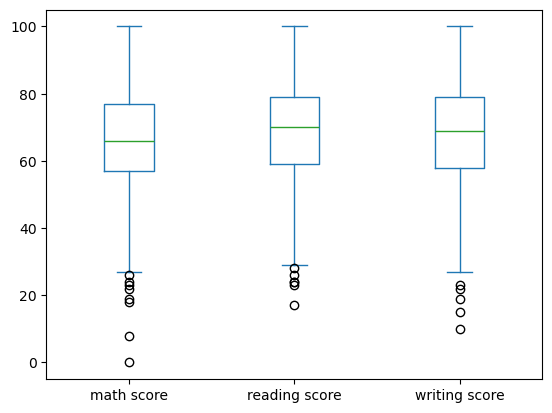

In [13]:
print(df[["math score","reading score","writing score"]].plot(kind='box'))

In [14]:
# IQR=Q3-Q1
#for iqr is 20,20,21.25
#for min plot= Q1-1.5*iqr math-27,reading-29,writing-25.875
#for max plot= Q3+1.5*iqr math-107,reading-109,writing-110.875
math_outlier=len(df[df["math score"]<27])
reading_outlier=len(df[df["reading score"]<29])
writing_outlier=len(df[df["writing score"]<25.875])
print(math_outlier," ",reading_outlier," ",writing_outlier)

8   6   5


In [15]:
df[(df["math score"]<27) & (df["reading score"]<29 )& (df["writing score"]<25.875)]

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
59,female,group C,some high school,free/reduced,none,0,17,10
980,female,group B,high school,free/reduced,none,8,24,23


so from the above obeservation i could say there are two students who are extremly poor in studies 

In [16]:
df_less_marks=df[(df["math score"]<27) | (df["reading score"]<29 ) | (df["writing score"]<25.875)]

In [17]:
df_less_marks

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
17,female,group B,some high school,free/reduced,none,18,32,28
59,female,group C,some high school,free/reduced,none,0,17,10
76,male,group E,some high school,standard,none,30,26,22
145,female,group C,some college,free/reduced,none,22,39,33
211,male,group C,some college,free/reduced,none,35,28,27
327,male,group A,some college,free/reduced,none,28,23,19
338,female,group B,some high school,free/reduced,none,24,38,27
466,female,group D,associate's degree,free/reduced,none,26,31,38
596,male,group B,high school,free/reduced,none,30,24,15
787,female,group B,some college,standard,none,19,38,32


so these were the potential outlier and from this we found some extremely poor students and most of them are fromt the group B<br> and yet group A average is still below group B so group is still performing better than group A but these students are even dragging that thing further down

<Axes: ylabel='Frequency'>

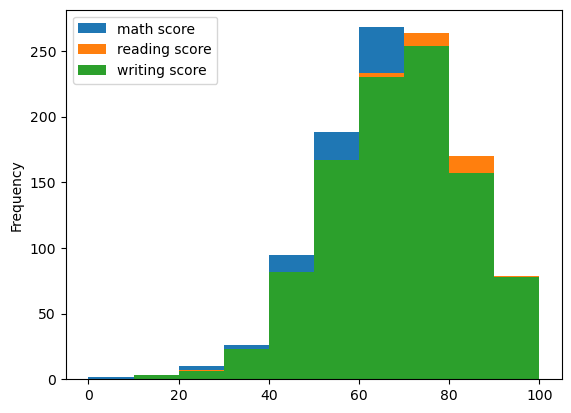

In [18]:
df.plot(kind="hist")

so overall writing score contain more students with higher marks and overall distribution is much toward higher marks

<Axes: xlabel='gender'>

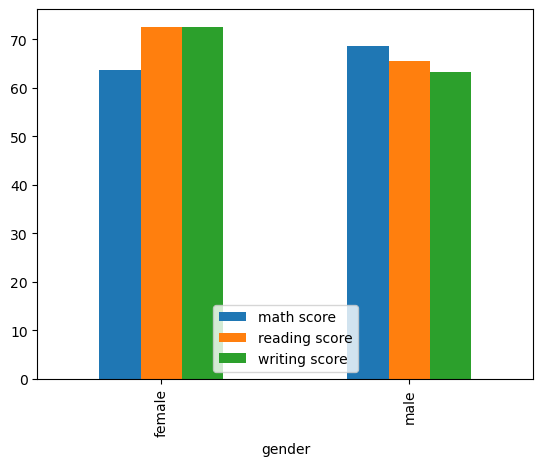

In [19]:
df.groupby("gender").mean(numeric_only=True).plot(kind="bar")

<Axes: xlabel='parental level of education'>

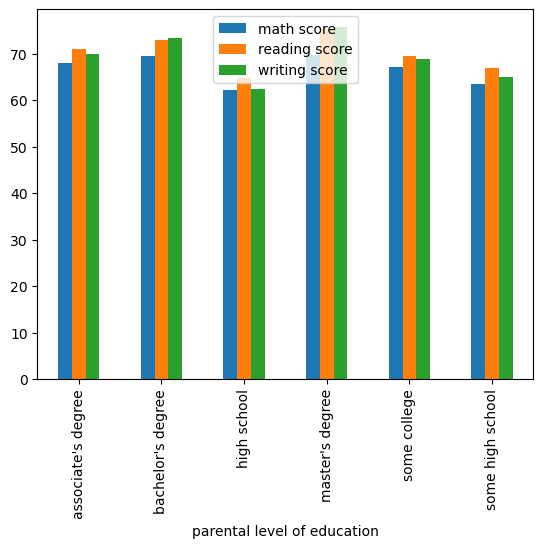

In [20]:
df.groupby("parental level of education").mean(numeric_only=True).plot(kind="bar")

<Axes: xlabel='lunch'>

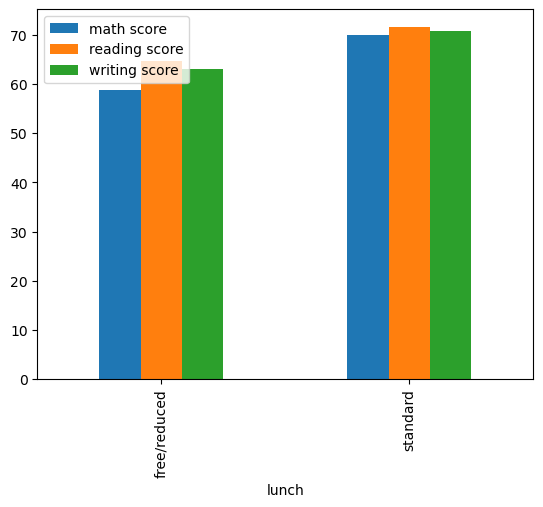

In [21]:
df.groupby("lunch").mean(numeric_only=True).plot(kind="bar")

Question 1: Why might we use a boxplot instead of simply looking at minimum, maximum, mean and median?

Question 2: You found that standard lunch students have higher average marks. What other column would you investigate to understand whether lunch type is associated with parental education?

Question 3: If the mean mathematics score is 66.09 and the median is 66, can we conclude that the distribution is symmetrical?


so you have asked about these questions and my answer to the first question is that boxplot will help understand and find outliers.
Which will help us to find the students who are weak and decreasing the overall avg of the data

for second i would say i will try to check for whether there is a relation between parental educationa and lunch and group so we could find that maybe some groups have students mostly containg parents with higher degree or lower degree or whether a person taking test preparation and lunch have to do anything with parental education 

for third i would not say the data is symmetrical rather the data is more rightly skewed

now i will further find some relation below--

In [22]:
df.pivot_table(index="parental level of education",columns="race/ethnicity",values=["math score","reading score","writing score"],aggfunc="mean")

math score                                   \
race/ethnicity                 group A    group B    group C    group D   
parental level of education                                               
associate's degree           61.000000  66.097561  66.730769  67.600000   
bachelor's degree            67.166667  69.300000  68.150000  67.571429   
high school                  60.444444  59.791667  60.906250  62.863636   
master's degree              57.666667  67.166667  67.052632  72.521739   
some college                 63.888889  63.189189  65.130435  68.731343   
some high school             58.916667  61.815789  60.551020  66.760000   

                                       reading score                        \
race/ethnicity                 group E       group A    group B    group C   
parental level of education                                                  
associate's degree           74.897436     67.071429  69.585366  71.128205   
bachelor's degree            76.555556     68.083333  72.950000  75.675000   
high school                  70.772727     62.888889  63.458333  64.421875   
master's degree              74.625000     64.666667  80.166667  70.526316   
some college                 73.828571     65.777778  65.756757  69.420290   
some high school             72.111111     62.083333  66.447368  65.632653   

                                                  writing score             \
race/ethnicity                 group D    group E       group A    group B   
parental level of education                                                  
associate's degree           70.540000  73.820513     63.571429  68.243902   
bachelor's degree            70.142857  74.833333     68.333333  71.650000   
high school                  64.409091  70.318182     60.500000  61.250000   
master's degree              77.173913  82.125000     67.666667  77.166667   
some college                 70.880597  72.628571     65.000000  64.189189   
some high school             69.980000  69.555556     58.583333  64.605263   

                                                              
race/ethnicity                 group C    group D    group E  
parental level of education                                   
associate's degree           70.269231  69.860000  73.205128  
bachelor's degree            75.900000  71.892857  75.388889  
high school                  61.656250  63.159091  67.545455  
master's degree              69.526316  79.739130  80.500000  
some college                 68.869565  71.701493  70.200000  
some high school             63.285714  69.100000  66.555556

by this obeservation i found that even though parental level effect the group score, group e are still performing exceptionally well.

In [23]:
df.groupby(["gender","race/ethnicity"]).size()

gender  race/ethnicity
female  group A            36
        group B           104
        group C           180
        group D           129
        group E            69
male    group A            53
        group B            86
        group C           139
        group D           133
        group E            71
dtype: int64

In [24]:
df.groupby(["race/ethnicity","parental level of education"]).size()

race/ethnicity  parental level of education
group A         associate's degree             14
                bachelor's degree              12
                high school                    18
                master's degree                 3
                some college                   18
                some high school               24
group B         associate's degree             41
                bachelor's degree              20
                high school                    48
                master's degree                 6
                some college                   37
                some high school               38
group C         associate's degree             78
                bachelor's degree              40
                high school                    64
                master's degree                19
                some college                   69
                some high school               49
group D         associate's degree             50
      

so from this i would say group d has potentially more people with high degree parents but the overall size of group d is much more than group e so even if high degree students perform better the overall students are dragging it down 

In [25]:
df.pivot_table(index="parental level of education",columns="lunch",values=["math score","reading score","writing score"])

math score            reading score             \
lunch                       free/reduced   standard  free/reduced   standard   
parental level of education                                                    
associate's degree             62.610390  70.682759     67.649351  72.668966   
bachelor's degree              63.000000  73.189189     68.931818  75.418919   
high school                    54.514286  66.373016     60.214286  67.198413   
master's degree                61.166667  75.628571     70.291667  78.857143   
some college                   60.126582  70.891156     65.075949  71.816327   
some high school               53.934426  68.440678     60.114754  70.466102   

                            writing score             
lunch                        free/reduced   standard  
parental level of education                           
associate's degree              66.025974  71.951724  
bachelor's degree               69.227273  75.851351  
high school                     57.400000  65.253968  
master's degree                 69.875000  79.657143  
some college                    63.708861  71.598639  
some high school                57.622951  68.644068

Apparantly everyone who has taken standard lunch is scoring higher than free lunch students despite being their parental level of education

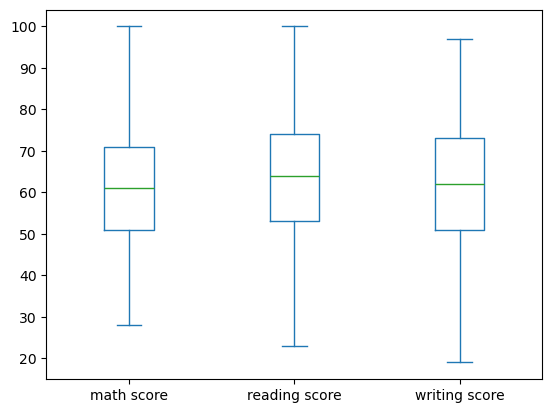

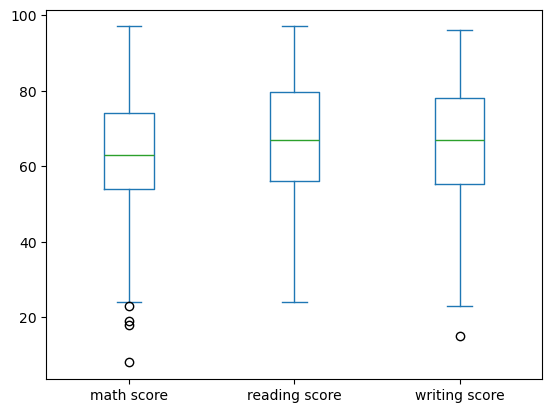

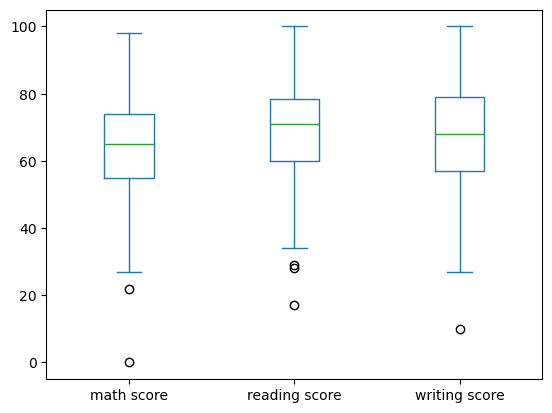

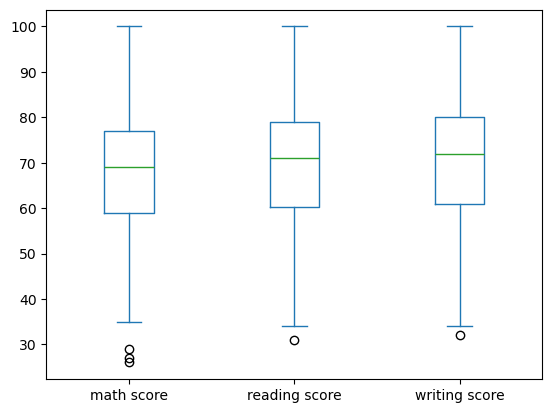

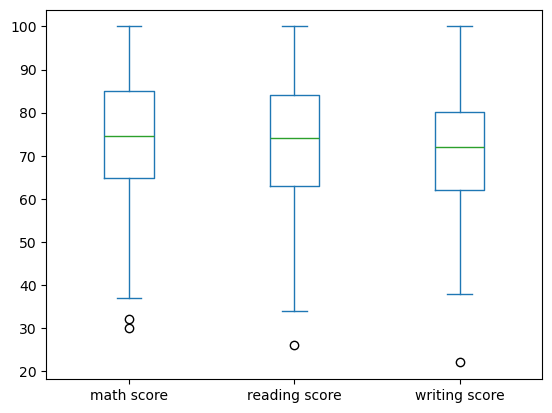

In [26]:
import matplotlib.pyplot as plt
df.groupby("race/ethnicity").plot(kind="box")
plt.show()

In [27]:
print(df["math score"].skew())
print(df["reading score"].skew())
print(df["writing score"].skew())

-0.27893514909431694
-0.25910451810923063
-0.28944397150761897


so overall i would say the skewness is in negative that means median has greater value then mean and there are some low value outliers that are decreasing the overall skewness

In [28]:
df

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75
...,...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77


So for the final summary --

The overall data state that female are performing better than male in both reading and writing.<br>
Group E is performing significantly better than other groups and group A is performing worse.<br>
Parental education is affecting overall students average score.<br>
Those who have taken standard lunch are perfoming significantly better than those who have taken free lunch.<br>
The students who have completed there test preparation course are perfoming better than those who have not completed.